# Simulator parameters

Parameters of the simulated detector measured on the real Walnut 1 data.

## 1a. Read noise and per-pixel offset

The difference of two darks cancels the fixed per-pixel offset and leaves only temporal noise:
var(D1 − D2) = 2 σ_read². Row offsets, column offsets and the slow component (residual image)
can change between orbits, so they are removed before measuring.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tifffile
from scipy.ndimage import gaussian_filter, median_filter

DATA = Path("~/dati/walnut/Walnut1/Projections/tubeV1").expanduser()
ROOT = DATA.parent
ORBITS = ["tubeV1", "tubeV2", "tubeV3"]

darks = {
    orb: tifffile.imread(ROOT / orb / "di000000.tif").astype(np.float64)
    for orb in ORBITS
}
for orb, d in darks.items():
    print(f"{orb}: shape {d.shape}, mean {d.mean():.1f}, std {d.std():.2f}")

<TiffTag.fromfile> raised TiffFileError('<tifffile.TiffTag 320 @1493217> invalid value offset 0')
<TiffTag.fromfile> raised TiffFileError('<tifffile.TiffTag 320 @1493217> invalid value offset 0')
<TiffTag.fromfile> raised TiffFileError('<tifffile.TiffTag 320 @1493217> invalid value offset 0')


tubeV1: shape (768, 972), mean 342.7, std 11.14
tubeV2: shape (768, 972), mean 359.4, std 11.60
tubeV3: shape (768, 972), mean 364.9, std 11.36


In [2]:
def clean(img, slow_sigma=15):
    """Remove row offsets, column offsets and the slow (large-scale) component."""
    out = img - img.mean(axis=1, keepdims=True)  # one mean per row
    out = out - out.mean(axis=0, keepdims=True)  # one mean per column
    return out - gaussian_filter(out, slow_sigma)


def spread(x):
    """Standard deviation and a robust version (half the 16-84 percentile range)."""
    p16, p84 = np.percentile(x, [16, 84])
    return x.std(), (p84 - p16) / 2

In [3]:
s_tot, s_tot_rob = spread(clean(darks["tubeV1"]))
print(f"single dark tubeV1 cleaned: std {s_tot:.2f}, robust {s_tot_rob:.2f}\n")

pairs = [("tubeV1", "tubeV2"), ("tubeV1", "tubeV3"), ("tubeV2", "tubeV3")]
for a, b in pairs:
    s, s_rob = spread(clean(darks[a] - darks[b]))
    print(f"{a} - {b}: sigma_read {s / np.sqrt(2):.2f}, robust {s_rob / np.sqrt(2):.2f}")

single dark tubeV1 cleaned: std 1.35, robust 1.27

tubeV1 - tubeV2: sigma_read 0.59, robust 0.58
tubeV1 - tubeV3: sigma_read 0.57, robust 0.57
tubeV2 - tubeV3: sigma_read 0.56, robust 0.55


In [4]:
for sig in [5, 10, 15, 30]:
    s, _ = spread(clean(darks["tubeV1"] - darks["tubeV2"], slow_sigma=sig))
    print(f"slow_sigma {sig:2d}: sigma_read {s / np.sqrt(2):.3f}")

slow_sigma  5: sigma_read 0.548
slow_sigma 10: sigma_read 0.563
slow_sigma 15: sigma_read 0.585
slow_sigma 30: sigma_read 0.662


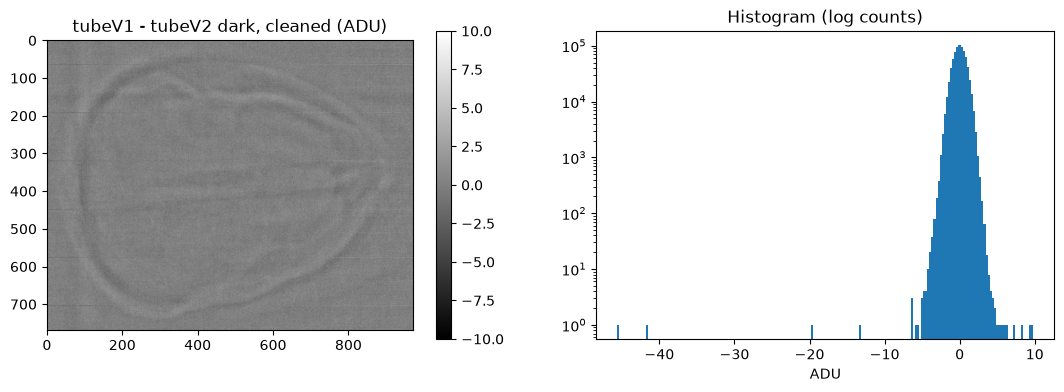

In [5]:
r = clean(darks["tubeV1"] - darks["tubeV2"])

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
im = ax[0].imshow(r, cmap="gray", vmin=-10, vmax=10)
ax[0].set_title("tubeV1 - tubeV2 dark, cleaned (ADU)")
fig.colorbar(im, ax=ax[0])
ax[1].hist(r.ravel(), bins=200, log=True)
ax[1].set_xlabel("ADU")
ax[1].set_title("Histogram (log counts)")
plt.show()

In [6]:
sigmas = [2, 3, 5, 10, 15, 30]
print("slow_sigma  read(V1-V2)  total(V1 alone)  offset")
for sig in sigmas:
    s_diff, _ = spread(clean(darks["tubeV1"] - darks["tubeV2"], slow_sigma=sig))
    s_one, _ = spread(clean(darks["tubeV1"], slow_sigma=sig))
    s_read = s_diff / np.sqrt(2)
    s_off = np.sqrt(s_one**2 - s_read**2)
    print(f"{sig:10d}  {s_read:11.3f}  {s_one:15.3f}  {s_off:6.3f}")

slow_sigma  read(V1-V2)  total(V1 alone)  offset
         2        0.527            1.279   1.166
         3        0.539            1.299   1.182
         5        0.548            1.312   1.192
        10        0.563            1.327   1.202
        15        0.585            1.352   1.219
        30        0.662            1.495   1.341


In [7]:
SLOW_SIGMA = 3  # small enough to remove the walnut edges; noise loss corrected below


def keep_factor(s):
    """Fraction of white-noise std that survives clean() with slow_sigma = s."""
    return np.sqrt(1 - 3 / (4 * np.pi * s**2))


k = keep_factor(SLOW_SIGMA)
reads = []
for a, b in [("tubeV1", "tubeV2"), ("tubeV1", "tubeV3"), ("tubeV2", "tubeV3")]:
    s, _ = spread(clean(darks[a] - darks[b], slow_sigma=SLOW_SIGMA))
    reads.append(s / np.sqrt(2) / k)
    print(f"{a} - {b}: sigma_read (corrected) {reads[-1]:.3f}")

sigma_read_meas = np.mean(reads)  # includes quantisation: compare with simulated data
s_one, _ = spread(clean(darks["tubeV1"], slow_sigma=SLOW_SIGMA))
total = s_one / k
offset_px = np.sqrt(total**2 - sigma_read_meas**2)
sigma_read_sim = np.sqrt(sigma_read_meas**2 - 1 / 12)  # stage 7: rounding added at stage 8

print(f"\nsigma_read measured (with rounding): {sigma_read_meas:.3f} ADU")
print(f"total per-pixel spread, one dark:     {total:.3f} ADU")
print(f"per-pixel offset (stage 6):           {offset_px:.3f} ADU")
print(f"electronic read noise (stage 7):      {sigma_read_sim:.3f} ADU")

tubeV1 - tubeV2: sigma_read (corrected) 0.547
tubeV1 - tubeV3: sigma_read (corrected) 0.542
tubeV2 - tubeV3: sigma_read (corrected) 0.538

sigma_read measured (with rounding): 0.542 ADU
total per-pixel spread, one dark:     1.317 ADU
per-pixel offset (stage 6):           1.200 ADU
electronic read noise (stage 7):      0.459 ADU


**Result 1a.** Read noise and per-pixel offset (slow_sigma = 3, noise loss of the filter corrected):

| Quantity | Value (ADU) | Use |
|---|---|---|
| σ_read measured, includes rounding | 0.542 | target for the simulator validation |
| Per-pixel offset | 1.20 | stage 6 |
| Electronic read noise, √(σ_read² − 1/12) | 0.459 | stage 7 (stage 8 adds the rounding) |

- The 2.5 ADU per-pixel spread found in Milestone 1 was mostly residual image: removing the slow
  component lowers it to 1.32 ADU.
- With slow_sigma ≥ 15 the walnut edges survive in the difference of two darks and inflate σ_read
  (0.66 at slow_sigma = 30).
- Offset level differs between orbits (342.7, 359.4, 364.9 ADU): the dark of one orbit must not be
  used for another.
- About ten pixels change offset by 10–45 ADU between orbits: candidates for Milestone 3.

std of row means (raw):        10.48 ADU
std of fast row offsets:       8.43 ADU
std of row-to-row jumps, raw:  12.34 ADU
std of row-to-row jumps, fast: 12.34 ADU
correlation tubeV1 vs tubeV2:  1.000

row_sigma  5: std of fast row offsets 8.20 ADU
row_sigma 10: std of fast row offsets 8.43 ADU
row_sigma 20: std of fast row offsets 8.55 ADU
row_sigma 40: std of fast row offsets 8.64 ADU


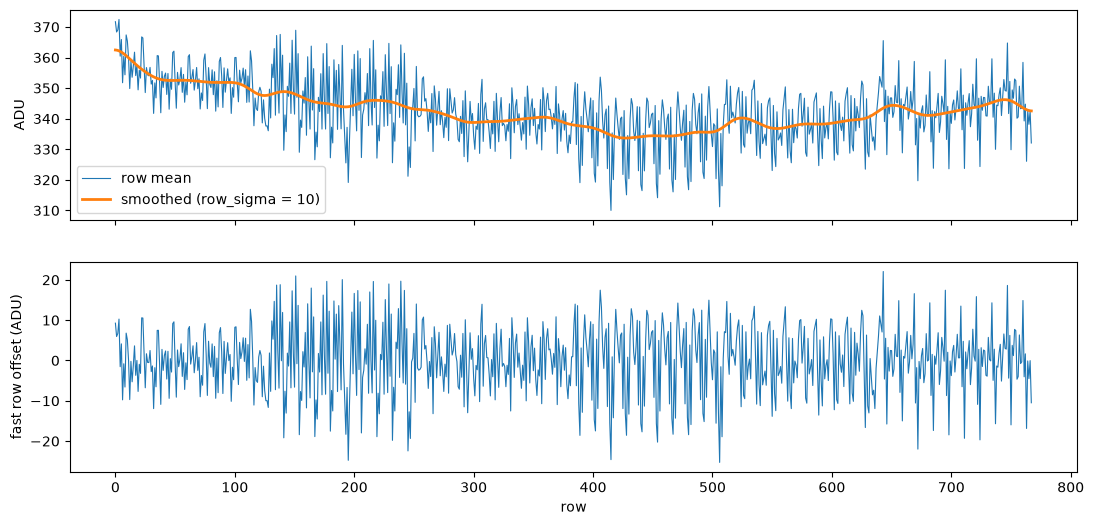

In [8]:
from scipy.ndimage import gaussian_filter1d

ROW_SIGMA = 10  # rows; the smooth part of the row means is residual image


def fast_rows(dark, row_sigma=ROW_SIGMA):
    """Row means minus their smoothed version: fast row-to-row offsets."""
    m = dark.mean(axis=1)  # one value per row (768)
    return m - gaussian_filter1d(m, row_sigma), m


fast1, m1 = fast_rows(darks["tubeV1"])
fast2, _ = fast_rows(darks["tubeV2"])

print(f"std of row means (raw):        {m1.std():.2f} ADU")
print(f"std of fast row offsets:       {fast1.std():.2f} ADU")
print(f"std of row-to-row jumps, raw:  {np.diff(m1).std():.2f} ADU")
print(f"std of row-to-row jumps, fast: {np.diff(fast1).std():.2f} ADU")
print(f"correlation tubeV1 vs tubeV2:  {np.corrcoef(fast1, fast2)[0, 1]:.3f}\n")

for s in [5, 10, 20, 40]:
    f, _ = fast_rows(darks["tubeV1"], s)
    print(f"row_sigma {s:2d}: std of fast row offsets {f.std():.2f} ADU")

rows = np.arange(m1.size)
fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
ax[0].plot(rows, m1, lw=0.8, label="row mean")
ax[0].plot(rows, m1 - fast1, lw=2, label=f"smoothed (row_sigma = {ROW_SIGMA})")
ax[0].set_ylabel("ADU")
ax[0].legend()
ax[1].plot(rows, fast1, lw=0.8)
ax[1].set_xlabel("row")
ax[1].set_ylabel("fast row offset (ADU)")
plt.show()

In [9]:
ROW_SIGMA = 20  # eats 1.3% of the stripes, no sign of the slow part leaking in
row_offsets, _ = fast_rows(darks["tubeV1"], ROW_SIGMA)

print(f"row offsets: {row_offsets.size} values, std {row_offsets.std():.2f} ADU")
print(f"std of row-to-row jumps: {np.diff(row_offsets).std():.2f} ADU (real dark: 12.34)")

row offsets: 768 values, std 8.55 ADU
std of row-to-row jumps: 12.34 ADU (real dark: 12.34)


## 1b. Row offsets

Row means of the dark = fixed row offsets (fast) + residual image (slow). The fast part is the
row means minus their Gaussian-smoothed version (row_sigma = 20 rows); these 768 values are the
true row offsets of the simulator (stage 6).

- Row offsets are independent from row to row: std of the jumps / √2 = 8.73 ADU, std of the
  offsets corrected for the part removed by the smoothing = 8.66 ADU.
- The pattern is identical in the darks of different orbits (correlation 1.000); only the mean
  level changes. Row offsets are a fixed property of the detector.
- Validation target for the simulated dark: std of the row-to-row jumps = 12.34 ADU.

<TiffTag.fromfile> raised TiffFileError('<tifffile.TiffTag 320 @1493217> invalid value offset 0')
<TiffTag.fromfile> raised TiffFileError('<tifffile.TiffTag 320 @1493217> invalid value offset 0')


std of rel, whole image: 0.62 %
std of rel, crop:        0.53 %


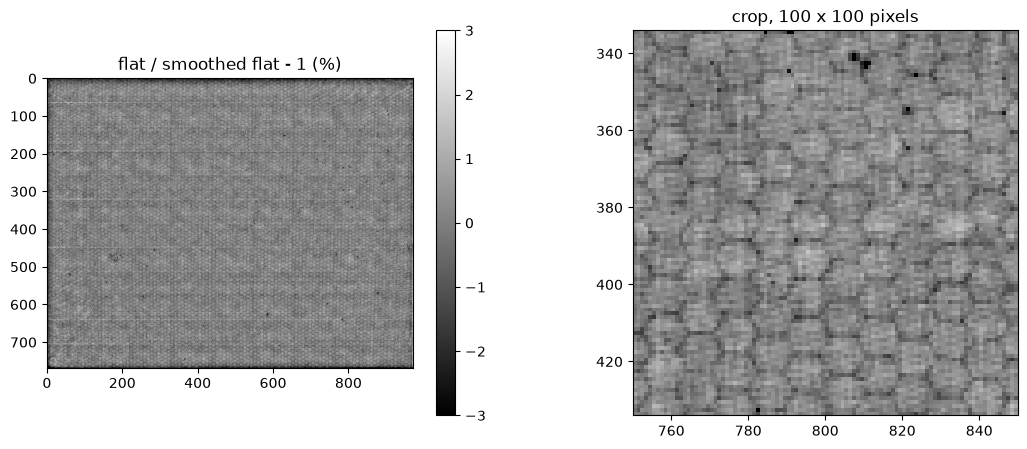

In [10]:
flats = [
    tifffile.imread(DATA / f"io00000{i}.tif").astype(np.float64) for i in (0, 1)
]
signal = (flats[0] + flats[1]) / 2 - darks["tubeV1"]  # mean of the two flats, dark removed
beam = gaussian_filter(signal, 15)                     # smooth part: beam profile
rel = signal / beam - 1                                # relative deviation (0.01 = 1%)

print(f"std of rel, whole image: {100 * rel.std():.2f} %")

r0, c0 = 334, 750  # 100 x 100 crop where the beam is brightest
crop = rel[r0:r0 + 100, c0:c0 + 100]
print(f"std of rel, crop:        {100 * crop.std():.2f} %")

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
im = ax[0].imshow(100 * rel, cmap="gray", vmin=-3, vmax=3)
ax[0].set_title("flat / smoothed flat - 1 (%)")
fig.colorbar(im, ax=ax[0])
ax[1].imshow(100 * crop, cmap="gray", vmin=-3, vmax=3,
             extent=[c0, c0 + 100, r0 + 100, r0])  # axis labels = real row/column numbers
ax[1].set_title("crop, 100 x 100 pixels")
plt.show()

## 1c. Gain map: hexagonal pattern

Relative gain map: rel = (mean flat − dark) / Gaussian-smoothed version (σ = 15 px) − 1.

- Hexagonal cells, ~10 px between centres vertically and ~8.7 px between columns horizontally
  (ratio √3/2 of a regular honeycomb, columns staggered). Cell size ≈ 1.5 mm, i.e. ~20 physical
  pixels. Expected NPS peak near 0.1 cycles/pixel (Milestone 4).
- Std of rel: 0.53 % in a bright 100 × 100 crop, 0.62 % over the whole image (the by-eye estimate
  of 1–2 % was too high). Quantum noise contributes ~0.05 %, i.e. ~1 % of the variance: the
  pattern is fixed.
- Decision: the simulator uses the measured map itself (option B), after replacing anomalous
  pixels, replicated in 2×2 blocks on the physical grid. Binning then returns the measured map
  exactly. A synthetic honeycomb was not used: flat-field correction removes any multiplicative
  pattern, so the choice cannot change the calibration results.

dim   : beam   8439 ADU, stripes std 28.34 ADU = 0.235 %
bright: beam  12730 ADU, stripes std 46.15 ADU = 0.258 %


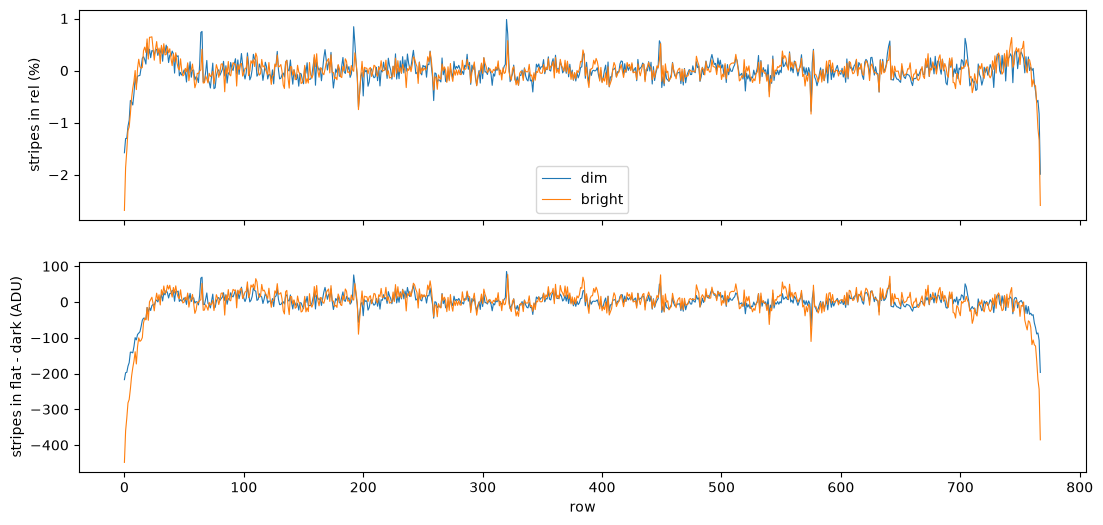

In [11]:
def fast_profile(img, cols, row_sigma=ROW_SIGMA):
    """Mean of each row over the given columns, minus its smoothed version."""
    m = img[:, cols].mean(axis=1)
    return m - gaussian_filter1d(m, row_sigma)


zones = {"dim": slice(30, 230), "bright": slice(700, 900)}  # skip the first ~20 edge columns
prof_adu, prof_rel = {}, {}
for name, cols in zones.items():
    prof_adu[name] = fast_profile(signal, cols)
    prof_rel[name] = fast_profile(rel, cols)
    print(f"{name:6s}: beam {beam[:, cols].mean():6.0f} ADU, "
          f"stripes std {prof_adu[name].std():5.2f} ADU = {100 * prof_rel[name].std():.3f} %")

fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
for name in zones:
    ax[0].plot(100 * prof_rel[name], lw=0.8, label=name)
    ax[1].plot(prof_adu[name], lw=0.8, label=name)
ax[0].set_ylabel("stripes in rel (%)")
ax[1].set_ylabel("stripes in flat - dark (ADU)")
ax[1].set_xlabel("row")
ax[0].legend()
plt.show()

## 1d. Horizontal lines in the gain map: gain or offset?

Test: the lines are compared where the beam is weak (columns 30–229, 8439 ADU) and strong
(columns 700–899, 12730 ADU). A gain effect scales with the beam (same in %), an offset does not
(same in ADU).

- Ratio strong/weak: 1.63 in ADU (beam ratio 1.51), 1.10 in % → multiplicative: the lines stay
  in the gain map.
- Isolated lines roughly every 128 rows (≈ 64, 192, 320, 448, 576, 704), probably readout-block
  boundaries.
- The first and last ~20 rows drop by up to 2.6 %: detector edge or smoothing artefact, to check.

blocks: 48 x 60
old fit, same blocks: slope 0.0073, intercept -10.9 ADU²
median var/mean: raw 0.00619, d 0.00613
robust spread of residuals (d): 18.5 %
raw: blocks above +30 %:  8.4%, correlation with drift step: +0.22
d  : blocks above +30 %:  8.2%, correlation with drift step: +0.11


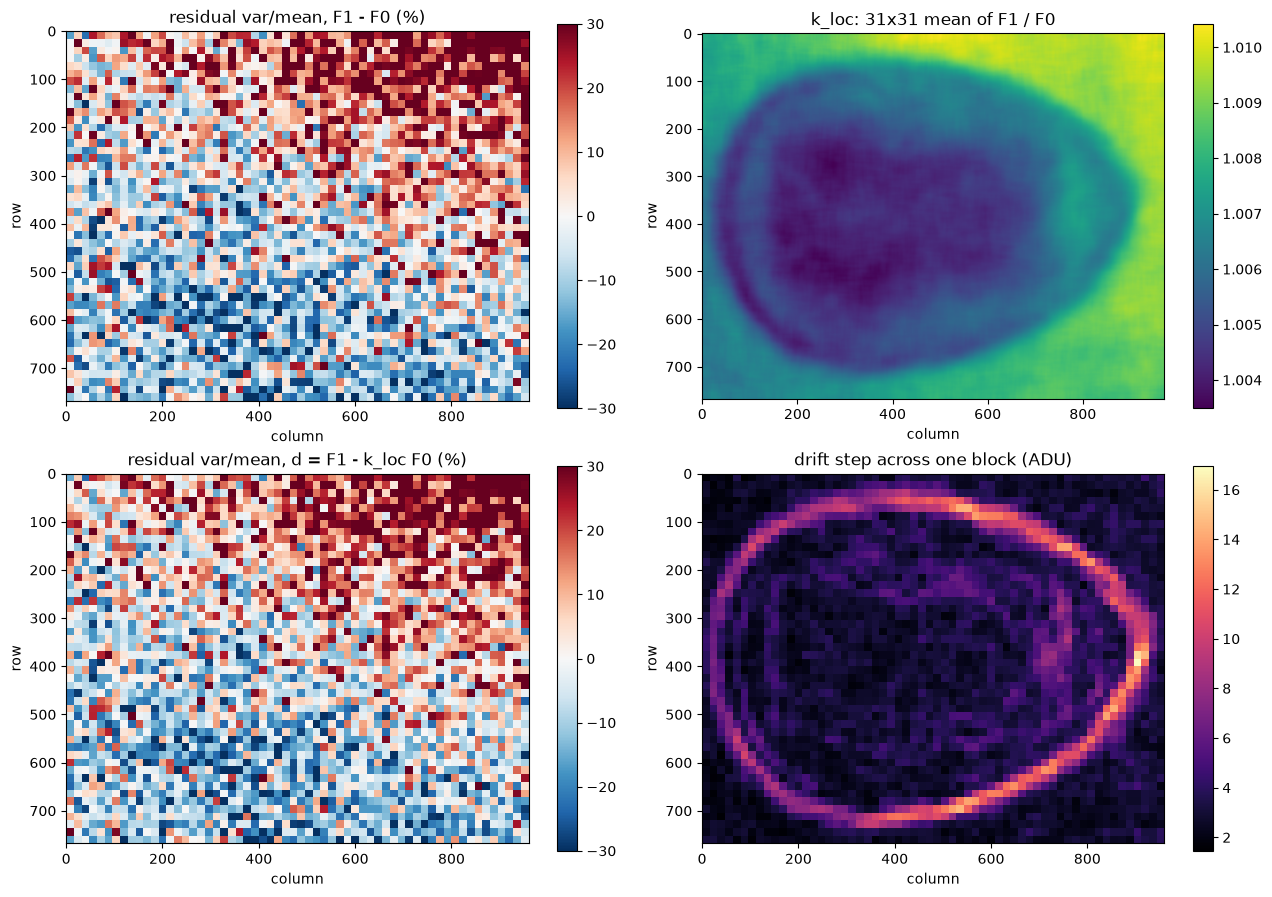

In [12]:
import itertools

from scipy.ndimage import uniform_filter

B = 16  # block size (binned pixels)
dark1 = darks["tubeV1"]
F0 = flats[0] - dark1  # flat before the scan, dark removed (ADU)
F1 = flats[1] - dark1  # flat after the scan
k_loc = uniform_filter(F1 / F0, size=31)  # smooth drift factor, ~1.0035-1.0101


def blocks(img, b=B):
    """View img as (block_row, row_in_block, block_col, col_in_block)."""
    nr, nc = img.shape[0] // b, img.shape[1] // b
    return img[: nr * b, : nc * b].reshape(nr, b, nc, b)


def block_mean(img):
    return blocks(img).mean(axis=(1, 3))


def block_var(img):
    return blocks(img).var(axis=(1, 3))


mean_map = 0.5 * (block_mean(F0) + block_mean(F1))  # 48 x 60, ADU
k_blk = block_mean(k_loc)

var_raw = block_var(F1 - F0) / 2  # as in notebook 01 (ADU²)
d = F1 - k_loc * F0  # difference with the local drift removed
var_d = block_var(d) / (2 * k_blk)  # normalised so that var_d / mean = k_eff

q_raw = var_raw / mean_map  # var/mean of each block
q_d = var_d / mean_map
res_raw = q_raw / np.median(q_raw) - 1  # 0.25 = 25 % above the typical block
res_d = q_d / np.median(q_d) - 1

gy, gx = np.gradient(k_loc)  # derivative along rows, along columns
step_blk = block_mean(np.hypot(gy, gx) * F0) * B  # drift step across one block (ADU)

slope, intercept = np.polyfit(mean_map.ravel(), var_raw.ravel(), 1)
print(f"blocks: {mean_map.shape[0]} x {mean_map.shape[1]}")
print(f"old fit, same blocks: slope {slope:.4f}, intercept {intercept:.1f} ADU²")
print(f"median var/mean: raw {np.median(q_raw):.5f}, d {np.median(q_d):.5f}")
p16, p84 = np.percentile(res_d, [16, 84])
print(f"robust spread of residuals (d): {100 * (p84 - p16) / 2:.1f} %")
for name, res in [("raw", res_raw), ("d", res_d)]:
    print(f"{name:3s}: blocks above +30 %: {np.mean(res > 0.3):5.1%}, "
          f"correlation with drift step: {np.corrcoef(res.ravel(), step_blk.ravel())[0, 1]:+.2f}")

ext = [0, mean_map.shape[1] * B, mean_map.shape[0] * B, 0]  # block maps in pixel coordinates
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
panels = [
    (ax[0, 0], 100 * res_raw, "residual var/mean, F1 - F0 (%)",
     {"cmap": "RdBu_r", "vmin": -30, "vmax": 30, "extent": ext}),
    (ax[0, 1], k_loc, "k_loc: 31x31 mean of F1 / F0", {"cmap": "viridis"}),
    (ax[1, 0], 100 * res_d, "residual var/mean, d = F1 - k_loc F0 (%)",
     {"cmap": "RdBu_r", "vmin": -30, "vmax": 30, "extent": ext}),
    (ax[1, 1], step_blk, "drift step across one block (ADU)", {"cmap": "magma", "extent": ext}),
]
for a, img, title, kw in panels:
    im = a.imshow(img, **kw)
    a.set_title(title)
    a.set_xlabel("column")
    a.set_ylabel("row")
    fig.colorbar(im, ax=a)
plt.tight_layout()
plt.show()

tiles (12, 15): var/mean 5th-95th percentile 0.00519 - 0.00780, peak-to-peak 50 %

signal bin (ADU)   blocks  median var/mean
  6239 -   8652      480  0.00596 +- 0.00005
  8652 -  10091      480  0.00583 +- 0.00006
 10091 -  11268      480  0.00613 +- 0.00008
 11268 -  12214      480  0.00606 +- 0.00008
 12214 -  13051      480  0.00627 +- 0.00006
 13051 -  13806      480  0.00653 +- 0.00005

same signal (11268 ADU +- 5 %):
  top    (row < 384) :  256 blocks, median var/mean 0.00706 +- 0.00010
  bottom (row >= 384):  279 blocks, median var/mean 0.00534 +- 0.00006
  left   (col < 486) :  236 blocks, median var/mean 0.00589 +- 0.00008
  right  (col >= 486):  299 blocks, median var/mean 0.00636 +- 0.00012


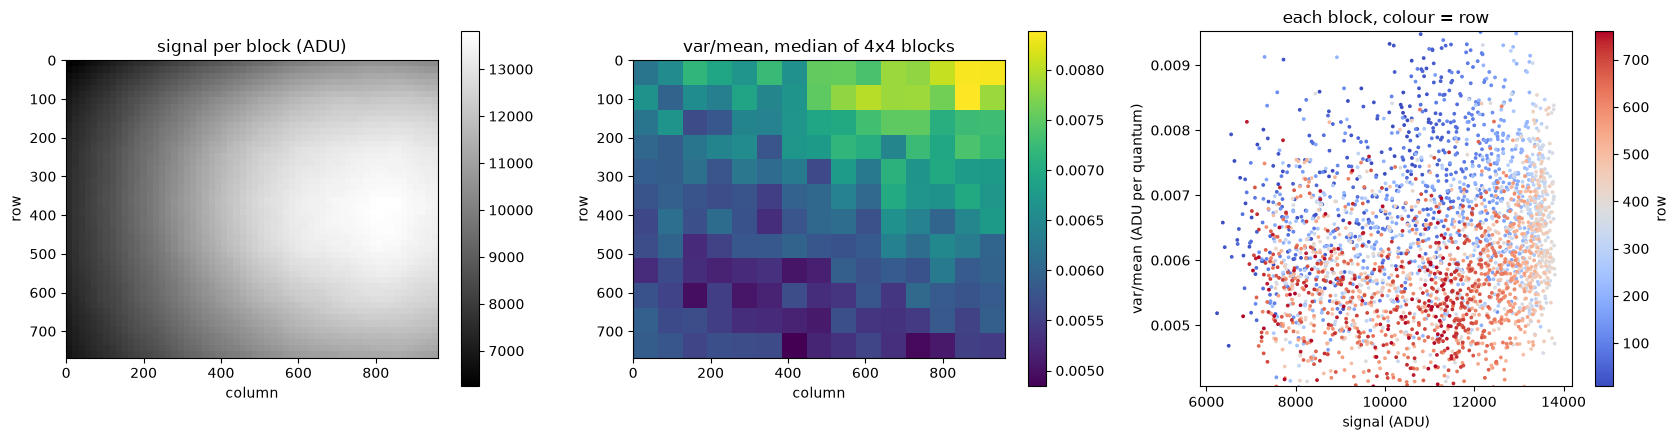

In [13]:
T = 4  # tile = 4 x 4 blocks = 64 x 64 pixels


def tiles(m, t=T):
    """Median of each t x t group of blocks."""
    nr, nc = m.shape[0] // t, m.shape[1] // t
    return np.median(m[: nr * t, : nc * t].reshape(nr, t, nc, t), axis=(1, 3))


def median_se(x):
    """Median and its standard error (1.25 x robust spread / sqrt(n))."""
    p16, p84 = np.percentile(x, [16, 84])
    return np.median(x), 1.25 * (p84 - p16) / 2 / np.sqrt(x.size)


rows_b, cols_b = (np.indices(mean_map.shape) + 0.5) * B  # centre of each block (pixels)

q_tile = tiles(q_d)  # 12 x 15 map of var/mean
lo, hi = np.percentile(q_tile, [5, 95])
print(f"tiles {q_tile.shape}: var/mean 5th-95th percentile {lo:.5f} - {hi:.5f}, "
      f"peak-to-peak {100 * (hi / lo - 1):.0f} %")

edges = np.percentile(mean_map, np.linspace(0, 100, 7))  # 6 bins, same number of blocks
print("\nsignal bin (ADU)   blocks  median var/mean")
for a, b in itertools.pairwise(edges):
    m, se = median_se(q_d[(mean_map >= a) & (mean_map <= b)])
    print(f"{a:6.0f} - {b:6.0f}   {((mean_map >= a) & (mean_map <= b)).sum():6d}  {m:.5f} +- {se:.5f}")

s_med = np.median(mean_map)
band = np.abs(mean_map / s_med - 1) < 0.05  # blocks within +-5 % of the median signal
print(f"\nsame signal ({s_med:.0f} ADU +- 5 %):")
for name, sel in [("top    (row < 384) ", rows_b < 384), ("bottom (row >= 384)", rows_b >= 384),
                  ("left   (col < 486) ", cols_b < 486), ("right  (col >= 486)", cols_b >= 486)]:
    m, se = median_se(q_d[band & sel])
    print(f"  {name}: {(band & sel).sum():4d} blocks, median var/mean {m:.5f} +- {se:.5f}")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
im = ax[0].imshow(mean_map, cmap="gray", extent=ext)
ax[0].set_title("signal per block (ADU)")
fig.colorbar(im, ax=ax[0])
im = ax[1].imshow(q_tile, cmap="viridis", extent=ext)
ax[1].set_title("var/mean, median of 4x4 blocks")
fig.colorbar(im, ax=ax[1])
for a in ax[:2]:
    a.set_xlabel("column")
    a.set_ylabel("row")
sc = ax[2].scatter(mean_map.ravel(), q_d.ravel(), c=rows_b.ravel(), s=3, cmap="coolwarm")
ax[2].set_ylim(np.percentile(q_d, [1, 99]))
ax[2].set_xlabel("signal (ADU)")
ax[2].set_ylabel("var/mean (ADU per quantum)")
ax[2].set_title("each block, colour = row")
fig.colorbar(sc, ax=ax[2], label="row")
plt.tight_layout()
plt.show()

In [14]:
def rho1(x):
    """Correlation with the right neighbour and with the neighbour below."""
    x = x - x.mean()
    return np.mean(x[:, :-1] * x[:, 1:]) / x.var(), np.mean(x[:-1, :] * x[1:, :]) / x.var()


# Lookup table from simulated white noise: Gaussian blur on the physical grid, then 2x2 mean binning
SIGMA_TAB = np.array([0.0, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5,
                      1.6, 1.7, 1.8, 1.9, 2.0])  # physical pixels
RHO_TAB = np.array([0.0, 0.041, 0.117, 0.197, 0.268, 0.334, 0.396, 0.454, 0.508, 0.556,
                    0.599, 0.637, 0.671, 0.701, 0.728, 0.751, 0.772, 0.791])
RBLUR_TAB = np.array([1.0, 0.851, 0.654, 0.513, 0.419, 0.350, 0.296, 0.252, 0.216, 0.187,
                      0.163, 0.144, 0.127, 0.113, 0.101, 0.091, 0.083, 0.075])

regions = {"top": d[16:368, 30:940], "bottom": d[400:752, 30:940]}  # skip filter borders and edge columns
r_blur = {}
for name, x in regions.items():
    rh, rv = rho1(x)
    sigma = np.interp((rh + rv) / 2, RHO_TAB, SIGMA_TAB)
    r_blur[name] = np.interp(sigma, SIGMA_TAB, RBLUR_TAB)
    print(f"{name:6s}: rho_1 horizontal {rh:.3f}, vertical {rv:.3f} "
          f"-> sigma_blur {sigma:.2f} physical px, R_blur {r_blur[name]:.3f}")

print(f"\nvar/mean top/bottom predicted from blur: {r_blur['top'] / r_blur['bottom']:.2f}")
print(f"var/mean top/bottom measured (step 3):   {0.00706 / 0.00534:.2f}")

top   : rho_1 horizontal 0.469, vertical 0.476 -> sigma_blur 1.03 physical px, R_blur 0.240
bottom: rho_1 horizontal 0.520, vertical 0.531 -> sigma_blur 1.14 physical px, R_blur 0.206

var/mean top/bottom predicted from blur: 1.17
var/mean top/bottom measured (step 3):   1.32


tubeV2 vs tubeV1: correlation 0.9996, slope 0.9972, std ratio 0.9976, residual std 0.226 ADU
tubeV3 vs tubeV1: correlation 0.9996, slope 0.9956, std ratio 0.9960, residual std 0.235 ADU


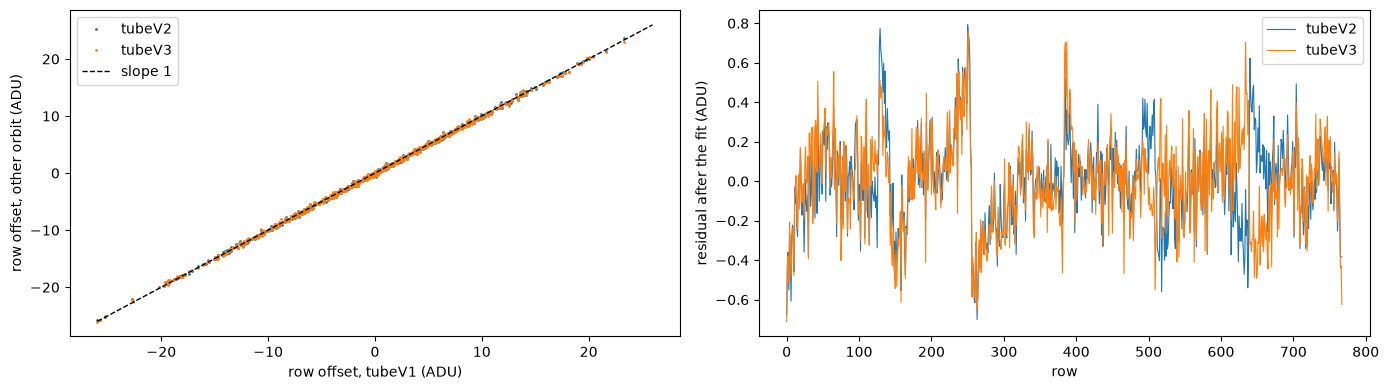

In [15]:
ref, _ = fast_rows(darks["tubeV1"], ROW_SIGMA)  # 768 row offsets of tubeV1 (ADU)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for orb in ["tubeV2", "tubeV3"]:
    other, _ = fast_rows(darks[orb], ROW_SIGMA)
    slope, intercept = np.polyfit(ref, other, 1)
    resid = other - (slope * ref + intercept)
    print(f"{orb} vs tubeV1: correlation {np.corrcoef(ref, other)[0, 1]:.4f}, "
          f"slope {slope:.4f}, std ratio {other.std() / ref.std():.4f}, "
          f"residual std {resid.std():.3f} ADU")
    ax[0].plot(ref, other, ".", ms=2, label=orb)
    ax[1].plot(resid, lw=0.8, label=orb)
lim = np.abs(ref).max()
ax[0].plot([-lim, lim], [-lim, lim], "k--", lw=1, label="slope 1")
ax[0].set_xlabel("row offset, tubeV1 (ADU)")
ax[0].set_ylabel("row offset, other orbit (ADU)")
ax[0].legend()
ax[1].set_xlabel("row")
ax[1].set_ylabel("residual after the fit (ADU)")
ax[1].legend()
plt.tight_layout()
plt.show()

sigma  5: rows 0-9 -0.27 %, rows 758-767 -0.15 %, width below -0.5 %: top 2 rows, bottom 1 rows
sigma 15: rows 0-9 -1.71 %, rows 758-767 -0.89 %, width below -0.5 %: top 15 rows, bottom 6 rows
sigma 30: rows 0-9 -3.79 %, rows 758-767 -1.83 %, width below -0.5 %: top 27 rows, bottom 16 rows


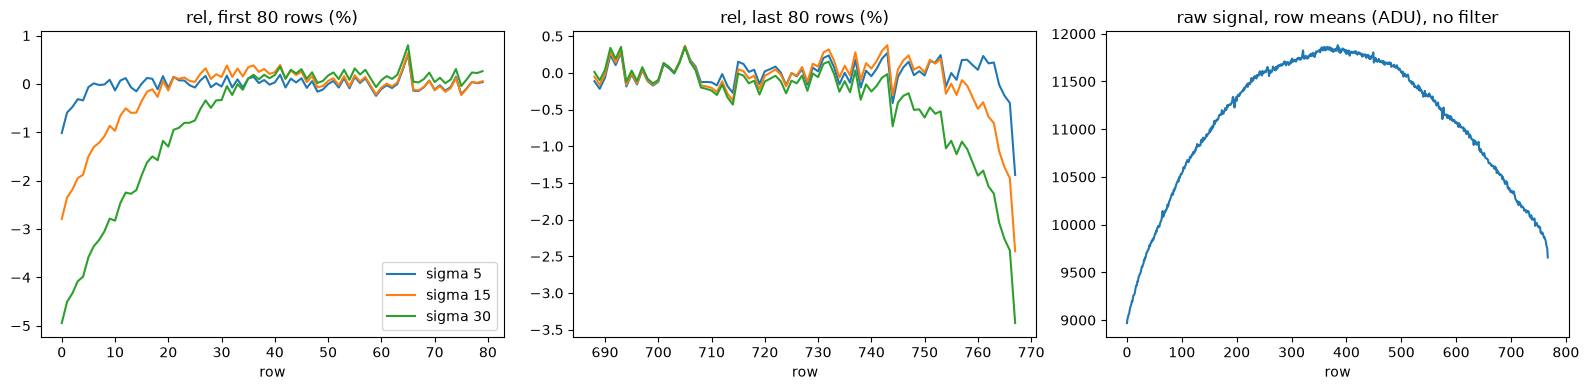

In [16]:
cols = slice(30, 940)  # skip the edge columns
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for s in [5, 15, 30]:
    prof = 100 * (signal / gaussian_filter(signal, s) - 1)[:, cols].mean(axis=1)  # % per row
    top_w = np.argmax(prof > -0.5)  # first row from the top above -0.5 %
    bot_w = np.argmax(prof[::-1] > -0.5)  # same, counting from the bottom
    print(f"sigma {s:2d}: rows 0-9 {prof[:10].mean():+.2f} %, rows 758-767 {prof[-10:].mean():+.2f} %, "
          f"width below -0.5 %: top {top_w} rows, bottom {bot_w} rows")
    ax[0].plot(prof[:80], label=f"sigma {s}")
    ax[1].plot(np.arange(688, 768), prof[688:], label=f"sigma {s}")
raw = signal[:, cols].mean(axis=1)
ax[2].plot(raw)
ax[0].set_title("rel, first 80 rows (%)")
ax[1].set_title("rel, last 80 rows (%)")
ax[2].set_title("raw signal, row means (ADU), no filter")
for a in ax:
    a.set_xlabel("row")
ax[0].legend()
plt.tight_layout()
plt.show()

col_sigma  std fast  even-odd  first 20 cols  corr V1-V2  corr V1-V3
       10      1.12      2.23           0.09       0.998       0.998
       20      1.14      2.23           0.42       0.992       0.997
       50      1.23      2.23           1.63       0.958       0.992
      100      1.57      2.23           3.66       0.893       0.986


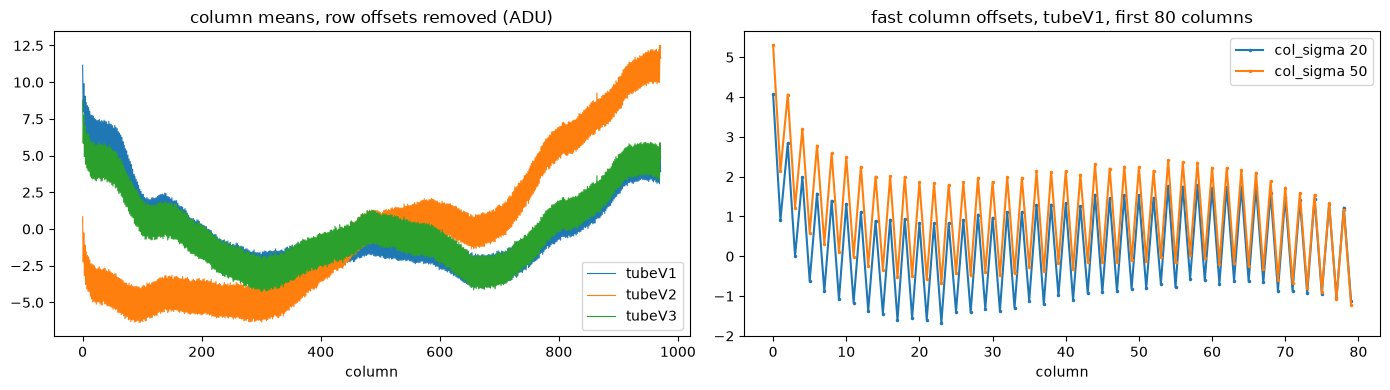

In [17]:
def col_means(dark):
    """Mean of each column after removing the row offsets (972 values, ADU)."""
    return (dark - dark.mean(axis=1, keepdims=True)).mean(axis=0)


cm = {orb: col_means(d) for orb, d in darks.items()}
print("col_sigma  std fast  even-odd  first 20 cols  corr V1-V2  corr V1-V3")
fast = {}
for s in [10, 20, 50, 100]:
    f = {orb: m - gaussian_filter1d(m, s) for orb, m in cm.items()}
    f1 = f["tubeV1"]
    even_odd = f1[30:940:2].mean() - f1[31:940:2].mean()  # skip the edge columns
    edge = f1[:20].mean() - f1[30:940].mean()
    print(f"{s:9d}  {f1.std():8.2f}  {even_odd:8.2f}  {edge:13.2f}  "
          f"{np.corrcoef(f1, f['tubeV2'])[0, 1]:10.3f}  {np.corrcoef(f1, f['tubeV3'])[0, 1]:10.3f}")
    fast[s] = f1

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for orb, m in cm.items():
    ax[0].plot(m, lw=0.8, label=orb)
ax[0].set_title("column means, row offsets removed (ADU)")
ax[0].legend()
for s in [20, 50]:
    ax[1].plot(fast[s][:80], ".-", ms=3, label=f"col_sigma {s}")
ax[1].set_title("fast column offsets, tubeV1, first 80 columns")
ax[1].legend()
for a in ax:
    a.set_xlabel("column")
plt.tight_layout()
plt.show()

In [18]:
def rho(x, dy, dx):
    """Correlation between each pixel and the one dy rows below, dx columns to the right (dx < 0: left)."""
    R, C = x.shape
    if dx >= 0:
        a, b = x[: R - dy, : C - dx], x[dy:, dx:]
    else:
        a, b = x[: R - dy, -dx:], x[dy:, : C + dx]
    return np.mean((a - x.mean()) * (b - x.mean())) / x.var()


lags = range(-10, 11)
sum_same_row = sum(rho(d, 0, k) for k in lags)  # S0: 1 + 2 x (rho at lags 1..10)
sum_next_row = sum(rho(d, 1, k) for k in lags)  # S1: same, with the row below
c = sum_next_row / sum_same_row  # correlation between adjacent row means
var_px = d.var()  # ADU², one pixel of the difference
n = d.shape[1]  # 972 pixels per row

white = np.sqrt(2 * var_px / n)  # old estimate: independent pixels
pred = np.sqrt(2 * var_px / n * sum_same_row * (1 - c))
meas = np.diff(d.mean(axis=1)).std()
print(f"var per pixel {var_px:.1f} ADU², S0 {sum_same_row:.2f}, S1 {sum_next_row:.2f}, c {c:.3f}")
print(f"jumps: independent pixels {white:.3f}, with correlation {pred:.3f}, measured on d {meas:.3f} ADU")
print("measured in notebook 01 on F1 - F0: 0.55 ADU")

var per pixel 141.6 ADU², S0 2.26, S1 1.28, c 0.569
jumps: independent pixels 0.540, with correlation 0.532, measured on d 0.531 ADU
measured in notebook 01 on F1 - F0: 0.55 ADU


## 1e. Anomalous pixels in the gain map

A pixel is anomalous if it differs from its neighbours along the row AND along the column (5-pixel medians):
score = min(|residual along the row|, |residual along the column|). The horizontal lines differ only along
the column and are kept.

- A threshold relative to the residual spread fails: the spread (0.256 %) is the hexagonal pattern itself,
  five times the quantum noise (0.05 %). With 5 robust σ, the row median alone flagged 4179 pixels (0.56 %);
  requiring both directions, 1421 (0.19 %): walls oblique to rows and columns are anomalous in both.
- Absolute threshold, as a fraction of the gain: 3385 pixels above 1 %, 630 above 2 %, 307 above 3 %,
  19 above 10 %. No plateau: the anomaly amplitudes are continuous.
- The 612 pixels above 2 % (away from the borders) are point defects, not walls: 99 % are dark, and their
  mean neighbourhood has the centre at −4.52 % with a one-pixel cross around it (≤ 1.14 %) and no line across
  the window. The cross is consistent with a defect blurred by the scintillator (expected neighbour
  0.31 × centre at σ_blur = 1.08); not followed up.
- Threshold 2 %: 630 pixels (0.084 %) replaced with the median along the row. Robust spread of the bright crop
  unchanged (0.467 → 0.466 %), row-line profiles unchanged; the std drops from 0.529 % to 0.487 % because the
  crop contains some of the defects.
- Weaker anomalies remain (e.g. row 329, column 121: −1.9 %). They are ten times smaller than the defects
  simulated in Milestone 3 (−12.5 % to −25 % after binning) and cannot become false positives there.
- The simulator uses rel_clean. The validation target for the gain pattern is the robust spread (0.47 %),
  which defects do not affect.

In [19]:
T_CLEAN = 0.02  # threshold for anomalous pixels, fraction of the gain (0.02 = 2 %)

res_row = rel - median_filter(rel, size=(1, 5))  # 1 x 5 window: along the row
res_col = rel - median_filter(rel, size=(5, 1))  # 5 x 1 window: along the column
score = np.minimum(np.abs(res_row), np.abs(res_col))  # large only if anomalous in both directions

# threshold relative to the robust spread (idea of 21/10, both directions): fails, see above
bad_sigma = (np.abs(res_row) > 5 * spread(res_row)[1]) & (np.abs(res_col) > 5 * spread(res_col)[1])
print(f"5 robust sigma, both directions: {bad_sigma.sum()} pixels ({100 * bad_sigma.mean():.3f} %)")

# absolute threshold, as a fraction of the gain (0.01 = 1 %)
for thr in [0.005, 0.01, 0.02, 0.03, 0.05, 0.10]:
    n = (score > thr).sum()
    print(f"threshold {100 * thr:4.1f} %: {n:6d} pixels ({100 * n / rel.size:.3f} %)")

5 robust sigma, both directions: 1421 pixels (0.190 %)
threshold  0.5 %:  28074 pixels (3.761 %)
threshold  1.0 %:   3385 pixels (0.453 %)
threshold  2.0 %:    630 pixels (0.084 %)
threshold  3.0 %:    307 pixels (0.041 %)
threshold  5.0 %:    106 pixels (0.014 %)
threshold 10.0 %:     19 pixels (0.003 %)


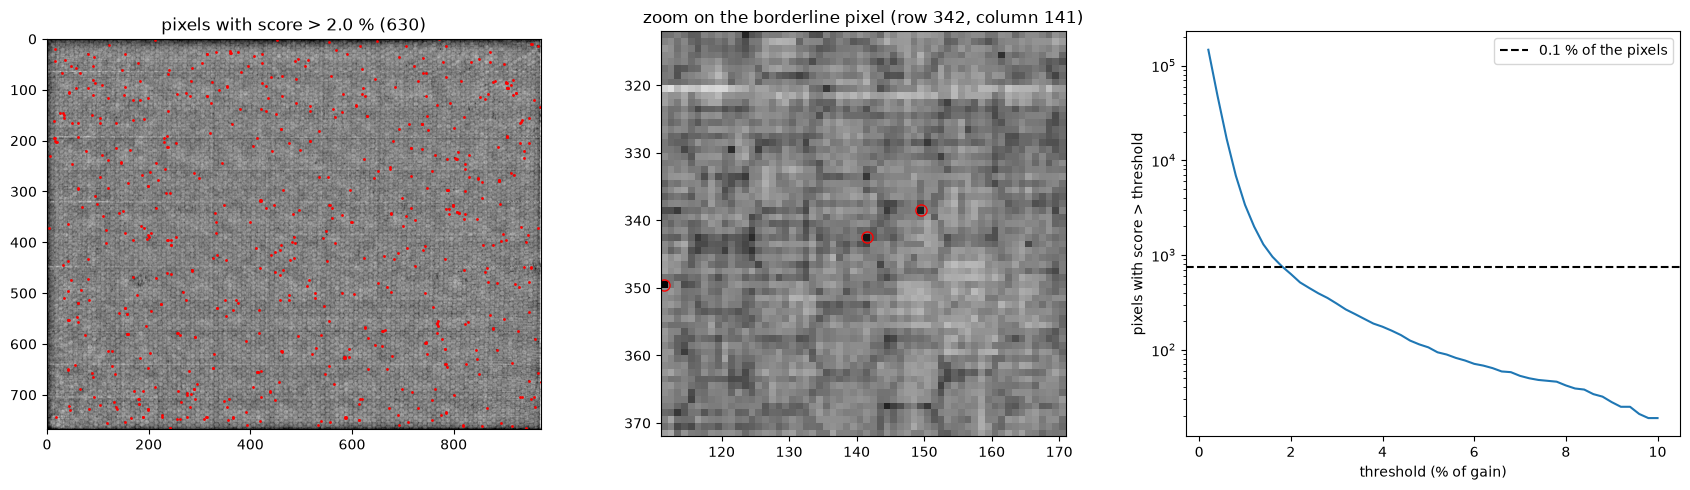

In [20]:
flag = score > T_CLEAN
thr_grid = np.linspace(0.002, 0.10, 50)
counts = [(score > t).sum() for t in thr_grid]

ys, xs = np.nonzero(flag)  # rows and columns of the flagged pixels
i_min = np.argmin(score[flag])  # borderline flagged pixel: wall or defect?
rb, cb = ys[i_min], xs[i_min]
r0, c0 = max(rb - 30, 0), max(cb - 30, 0)
zoom = (slice(r0, r0 + 60), slice(c0, c0 + 60))

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
ax[0].imshow(100 * rel, cmap="gray", vmin=-3, vmax=3)
ax[0].plot(xs, ys, "r.", ms=2)
ax[0].set_title(f"pixels with score > {100 * T_CLEAN:.1f} % ({flag.sum()})")
ax[1].imshow(100 * rel[zoom], cmap="gray", vmin=-3, vmax=3,
             extent=[c0, c0 + 60, r0 + 60, r0])  # axis labels = real row/column numbers
zy, zx = np.nonzero(flag[zoom])
ax[1].plot(c0 + zx + 0.5, r0 + zy + 0.5, "ro", mfc="none", ms=8)
ax[1].set_title(f"zoom on the borderline pixel (row {rb}, column {cb})")
ax[2].semilogy(100 * thr_grid, counts)
ax[2].axhline(0.001 * rel.size, color="k", ls="--", label="0.1 % of the pixels")
ax[2].set_xlabel("threshold (% of gain)")
ax[2].set_ylabel("pixels with score > threshold")
ax[2].legend()
plt.tight_layout()
plt.show()

612 pixels, 99 % dark; centre -4.52 %, largest |value| off centre 1.14 %


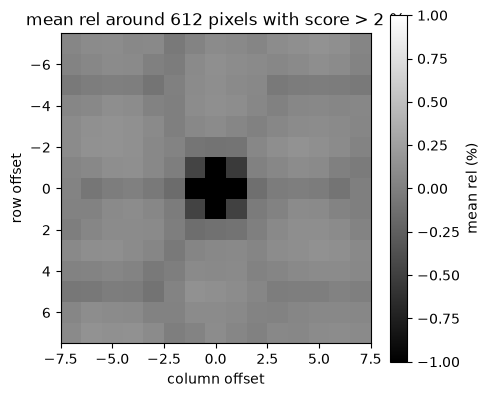

In [21]:
# mean neighbourhood of the flagged pixels: isolated point or wall?
h = 7  # half width: 15 x 15 window
ys, xs = np.nonzero(score > T_CLEAN)
keep = (ys >= h) & (ys < rel.shape[0] - h) & (xs >= h) & (xs < rel.shape[1] - h)  # skip the borders
ys, xs = ys[keep], xs[keep]
align = -np.sign(res_row[ys, xs])  # +1 for a dark anomaly, -1 for a bright one: bright ones are flipped
patch = np.mean([a * rel[y - h:y + h + 1, x - h:x + h + 1] for y, x, a in zip(ys, xs, align)], axis=0)
ring = np.abs(patch).copy()
ring[h, h] = 0  # everything except the centre
print(f"{ys.size} pixels, {100 * (align > 0).mean():.0f} % dark; centre {100 * patch[h, h]:.2f} %, "
      f"largest |value| off centre {100 * ring.max():.2f} %")

fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(100 * patch, cmap="gray", vmin=-1, vmax=1, extent=[-h - 0.5, h + 0.5, h + 0.5, -h - 0.5])
fig.colorbar(im, ax=ax, label="mean rel (%)")
ax.set_title(f"mean rel around {ys.size} pixels with score > {100 * T_CLEAN:.0f} %")
ax.set_xlabel("column offset")
ax.set_ylabel("row offset")
plt.show()

In [22]:
# replace the anomalous pixels with the median along the row (keeps the row lines)
bad = score > T_CLEAN
rel_clean = np.where(bad, median_filter(rel, size=(1, 5)), rel)

print(f"replaced {bad.sum()} pixels ({100 * bad.mean():.3f} %)")
box = (slice(334, 434), slice(750, 850))  # bright 100 x 100 crop of section 1c
for name, m in [("before", rel), ("after", rel_clean)]:
    s, s_rob = spread(m[box])
    print(f"{name:6s}: crop std {100 * s:.3f} %, robust {100 * s_rob:.3f} %")
for name, zcols in zones.items():  # dim / bright column zones of section 1d
    print(f"{name:6s}: row-line profile std before {100 * fast_profile(rel, zcols).std():.3f} %, "
          f"after {100 * fast_profile(rel_clean, zcols).std():.3f} %")

replaced 630 pixels (0.084 %)
before: crop std 0.529 %, robust 0.467 %
after : crop std 0.487 %, robust 0.466 %
dim   : row-line profile std before 0.235 %, after 0.234 %
bright: row-line profile std before 0.258 %, after 0.257 %


In [23]:
import json

PARAMS = Path("..") / "params"  # repository root / params (the notebook runs from notebooks/)
PARAMS.mkdir(exist_ok=True)


def entry(value, unit, stage, source):
    return {"value": value, "unit": unit, "stage": stage, "source": source}


params = {
    "meta": {
        "name": "walnut_tubeV1",
        "data": "Walnut 1, orbit tubeV1 (Der Sarkissian et al. 2019, CC BY 4.0)",
        "measured_in": "notebooks/02_simulator_parameters.ipynb",
        "physical_shape": [1536, 1944],
        "binned_shape": [768, 972],
    },
    # inputs of the simulator: what it is built from
    "true": {
        "g": entry(0.110, "ADU per quantum, physical pixel", 4,
                   "4 * k_eff / R_blur, assuming mean binning; field range 0.104-0.118"),
        "sigma_blur": entry(1.08, "physical pixels", 3,
                            "rho_1 = 0.50 with Gaussian PSF lookup; 1.03 top, 1.14 bottom"),
        "binning": entry(2, "pixels", 5, "fixed, mean of 2x2 (assumed)"),
        "offset_level": entry(342.7, "ADU", 6, "mean of the dark"),
        "offset_pixel_sigma": entry(1.20, "ADU", 6, "cleaned dark, read noise subtracted"),
        "read_noise": entry(0.459, "ADU", 7, "sqrt(0.542^2 - 1/12)"),
        "full_scale": entry(16383, "ADU", 8, "14-bit detector"),
        "flat_drift": entry(1.0064, "ratio flat1 / flat0", 1, "mean of (F1 - D) / (F0 - D), uniform part"),
        "seed": entry(0, "-", 2, "chosen"),
    },
    # what analysis of the real data gives: the simulated data must reproduce it
    "targets": {
        "k_eff_median": entry(0.0061, "ADU per quantum, binned", None, "median var/mean, 16x16 blocks of d"),
        "sigma_read_measured": entry(0.542, "ADU", None, "std(D1 - D2) / sqrt(2), three orbit pairs"),
        "offset_pixel_sigma": entry(1.20, "ADU", None, "same method as the input"),
        "row_jump_std_dark": entry(12.34, "ADU", None, "std of diff of dark row means"),
        "row_jump_std_diff": entry(0.531, "ADU", None, "std of diff of row means of d"),
        "rho_1": entry(0.50, "-", None, "neighbour correlation of d; 0.47 top, 0.53 bottom"),
        "gain_map_std": entry(0.0047, "fraction", None,
                              "robust spread (half 16-84 percentile range) of rel in the bright 100 x 100 crop"),
        "even_odd_offset": entry(2.23, "ADU", None, "mean of even minus odd fast column offsets, cols 30-939"),
    },
}

(PARAMS / "walnut_tubeV1.json").write_text(json.dumps(params, indent=2))
np.savez_compressed(
    PARAMS / "walnut_tubeV1_maps.npz",
    row_offsets=row_offsets,  # 768 values, ADU, stage 6
    gain_rel=rel_clean.astype(np.float32),  # 768 x 972, fraction, stage 4; 630 point defects (> 2 %) replaced
    beam=beam.astype(np.float32),  # 768 x 972, ADU, smooth part (sigma 15), stage 1: quanta = beam / g
    col_offsets=fast[20],  # 972 values, ADU, stage 6; col_sigma 20, edge tail underestimated
)
for f in sorted(PARAMS.iterdir()):
    print(f"{f.name}: {f.stat().st_size / 1e6:.2f} MB")

walnut_tubeV1.json: 0.00 MB
walnut_tubeV1_maps.npz: 5.28 MB
